In [2]:
# ==========================================
# CELL 1: Extract Uploaded Zip
# ==========================================
import zipfile
import os
import shutil

# Find any zip file in the current directory
zip_files = [f for f in os.listdir('.') if f.endswith('.zip')]

if not zip_files:
    print("❌ No .zip file found in /content. Check the left sidebar to make sure it finished uploading.")
else:
    zip_name = zip_files[0]
    print(f"📦 Found '{zip_name}'. Extracting now...")
    with zipfile.ZipFile(zip_name, 'r') as zip_ref:
        zip_ref.extractall(".")

    # If the zip extracted into a subfolder, move files to the main folder
    for item in os.listdir('.'):
        if os.path.isdir(item) and not item.startswith('.'):
            for sub_item in os.listdir(item):
                src = os.path.join(item, sub_item)
                dst = os.path.join('.', sub_item)
                if not os.path.exists(dst):
                    shutil.move(src, dst)

    print("✅ Done! Files ready for training:")
    for f in sorted(os.listdir('.')):
        if not f.startswith('.'):
            print(f"   - {f}")

📦 Found 'Multi-Horizon Quantile Forecasting.zip'. Extracting now...
✅ Done! Files ready for training:
   - Multi-Horizon Quantile Forecasting
   - Multi-Horizon Quantile Forecasting.zip
   - README.md
   - anscombe.json
   - california_housing_test.csv
   - california_housing_train.csv
   - dataset.py
   - mnist_test.csv
   - mnist_train_small.csv
   - sample_data
   - selected_pairs.csv
   - sequence_generation_multivariate_report.json
   - sequence_index_summary.csv
   - sequences_test.npz
   - sequences_train.npz
   - sequences_validation.npz
   - target_sales_scaler.joblib
   - test_split.csv
   - tft_model.py


In [3]:
# =====================================================================
# CELL 2: Hardware Setup, Categorical Embeddings & DataLoaders
# =====================================================================
import time
import random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

# 1. Reproducibility & Device Selection
SEED = 42
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Compute Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"   GPU Model: {torch.cuda.get_device_name(0)}")

# 2. Load sequence files with memory-mapping (instant loading, zero RAM overflow)
t0 = time.time()
print("\n1. Attaching sequence files via memory mapping...")
train_npz = np.load("sequences_train.npz", mmap_mode="r")
val_npz   = np.load("sequences_validation.npz", mmap_mode="r")
test_npz  = np.load("sequences_test.npz", mmap_mode="r")

static_cols = [
    "store_nbr", "item_nbr", "family", "class",
    "perishable", "city", "state", "type", "cluster"
]

# 3. Compute unique category cardinalities strictly from training sequences
print("2. Computing category cardinalities from training data...")
cat_categories = {}
cat_cardinalities = []

for col in static_cols:
    uniques = np.unique(train_npz[col])
    cat_categories[col] = uniques
    cat_cardinalities.append(len(uniques))
    print(f"   - {col:12s}: {len(uniques):3d} unique categories")

# 4. Define Memory-Mapped PyTorch Dataset
class TFTDataset(Dataset):
    def __init__(self, npz_data, cat_categories, static_cols):
        self.past_x = npz_data["past_x"]      # (N, 28, 18)
        self.future_x = npz_data["future_x"]  # (N, 7, 14)
        self.y = npz_data["y"]                # (N, 7)
        self.y_raw = npz_data["y_raw"]        # (N, 7)
        self.n_samples = len(self.y)

        # Pre-convert static columns into integer indices
        static_matrix = np.column_stack([
            pd.Categorical(npz_data[col], categories=cat_categories[col]).codes.astype(np.int64)
            for col in static_cols
        ])
        # Unseen categories default to index 0
        static_matrix = np.clip(static_matrix, a_min=0, a_max=None)
        self.static_x = torch.tensor(static_matrix, dtype=torch.long)

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        return {
            "past_x":   torch.tensor(self.past_x[idx],   dtype=torch.float32),
            "future_x": torch.tensor(self.future_x[idx], dtype=torch.float32),
            "static_x": self.static_x[idx],
            "y":        torch.tensor(self.y[idx],        dtype=torch.float32),
            "y_raw":    torch.tensor(self.y_raw[idx],    dtype=torch.float32)
        }

print("\n3. Initializing Train, Validation, and Test Datasets...")
train_dataset = TFTDataset(train_npz, cat_categories, static_cols)
val_dataset   = TFTDataset(val_npz,   cat_categories, static_cols)
test_dataset  = TFTDataset(test_npz,  cat_categories, static_cols)

# 5. DataLoaders
BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# 6. Sanity check shapes on a single batch
sample_batch = next(iter(train_loader))
print(f"\n4. Batch verification completed in {time.time() - t0:.2f}s:")
print(f"   - past_x shape:   {tuple(sample_batch['past_x'].shape)}   (Expected: [128, 28, 18])")
print(f"   - future_x shape: {tuple(sample_batch['future_x'].shape)}   (Expected: [128, 7, 14])")
print(f"   - static_x shape: {tuple(sample_batch['static_x'].shape)}   (Expected: [128, 9])")
print(f"   - y shape:        {tuple(sample_batch['y'].shape)}   (Expected: [128, 7])")
print(f"   - y_raw shape:    {tuple(sample_batch['y_raw'].shape)}   (Expected: [128, 7])")
print("STATUS: DataLoaders initialized successfully!")

✅ Compute Device: cuda
   GPU Model: Tesla T4

1. Attaching sequence files via memory mapping...
2. Computing category cardinalities from training data...
   - store_nbr   :  53 unique categories
   - item_nbr    : 122 unique categories
   - family      :  32 unique categories
   - class       :  65 unique categories
   - perishable  :   2 unique categories
   - city        :  22 unique categories
   - state       :  16 unique categories
   - type        :   5 unique categories
   - cluster     :  17 unique categories

3. Initializing Train, Validation, and Test Datasets...

4. Batch verification completed in 3.50s:
   - past_x shape:   (128, 28, 18)   (Expected: [128, 28, 18])
   - future_x shape: (128, 7, 14)   (Expected: [128, 7, 14])
   - static_x shape: (128, 9)   (Expected: [128, 9])
   - y shape:        (128, 7)   (Expected: [128, 7])
   - y_raw shape:    (128, 7)   (Expected: [128, 7])
STATUS: DataLoaders initialized successfully!


In [6]:
# =====================================================================
# CELL 3: Quantile Pinball Loss & TFT Architecture Setup
# =====================================================================
import torch
import torch.nn as nn
import joblib
from tft_model import TemporalFusionTransformer

# 1. Define Multi-Quantile Pinball Loss Function (P10, P50, P90)
class QuantileLoss(nn.Module):
    def __init__(self, quantiles=[0.1, 0.5, 0.9]):
        super().__init__()
        self.quantiles = quantiles

    def forward(self, preds, target):
        losses = []
        for i, q in enumerate(self.quantiles):
            error = target - preds[:, :, i]
            loss = torch.max((q - 1.0) * error, q * error)
            losses.append(loss.unsqueeze(-1))
        return torch.mean(torch.cat(losses, dim=-1))

# 2. Evaluation Metric Helper
def evaluate_quantiles(model, dataloader, criterion, device, target_scaler):
    model.eval()
    total_loss = 0.0
    all_p10_raw, all_p50_raw, all_p90_raw, all_y_raw = [], [], [], []

    with torch.no_grad():
        for batch in dataloader:
            past_x   = batch["past_x"].to(device)
            future_x = batch["future_x"].to(device)
            static_x = batch["static_x"].to(device)
            y        = batch["y"].to(device)
            y_raw    = batch["y_raw"].cpu().numpy()

            preds = model(past_x, future_x, static_x)
            loss  = criterion(preds, y)
            total_loss += loss.item() * len(y)

            # Invert predictions back to original grocery sales units
            p10_scaled = preds[:, :, 0].cpu().numpy()
            p50_scaled = preds[:, :, 1].cpu().numpy()
            p90_scaled = preds[:, :, 2].cpu().numpy()

            p10_raw = np.expm1(target_scaler.inverse_transform(p10_scaled)).clip(min=0.0)
            p50_raw = np.expm1(target_scaler.inverse_transform(p50_scaled)).clip(min=0.0)
            p90_raw = np.expm1(target_scaler.inverse_transform(p90_scaled)).clip(min=0.0)

            all_p10_raw.append(p10_raw)
            all_p50_raw.append(p50_raw)
            all_p90_raw.append(p90_raw)
            all_y_raw.append(y_raw)

    avg_loss = total_loss / len(dataloader.dataset)
    p10_all = np.vstack(all_p10_raw)
    p50_all = np.vstack(all_p50_raw)
    p90_all = np.vstack(all_p90_raw)
    y_all   = np.vstack(all_y_raw)

    total_actual = np.sum(y_all)
    wape = (np.sum(np.abs(y_all - p50_all)) / total_actual) * 100.0 if total_actual > 0 else 0.0
    inside_interval = (y_all >= p10_all) & (y_all <= p90_all)
    coverage = np.mean(inside_interval) * 100.0

    q10_risk = (2.0 * np.sum(np.maximum(0.1 * (y_all - p10_all), -0.9 * (y_all - p10_all)))) / total_actual
    q50_risk = (2.0 * np.sum(np.maximum(0.5 * (y_all - p50_all), -0.5 * (y_all - p50_all)))) / total_actual
    q90_risk = (2.0 * np.sum(np.maximum(0.9 * (y_all - p90_all), -0.1 * (y_all - p90_all)))) / total_actual

    return {
        "loss": avg_loss,
        "wape": wape,
        "coverage": coverage,
        "q10_risk": q10_risk,
        "q50_risk": q50_risk,
        "q90_risk": q90_risk
    }

# 3. Instantiate Champion TFT with YOUR EXACT OPTUNA HYPERPARAMETERS:
scaler_dict = joblib.load("target_sales_scaler.joblib")
target_scaler = scaler_dict["target_scaler"]
criterion = QuantileLoss(quantiles=[0.1, 0.5, 0.9])

champion_model = TemporalFusionTransformer(
    static_cardinalities=cat_cardinalities,
    hidden_size=32,      # EXACT OPTUNA BEST
    embedding_size=16,
    num_heads=2,        # EXACT OPTUNA BEST
    dropout=0.25,       # EXACT OPTUNA BEST
    forecast_horizon=7,
    num_quantiles=3
).to(DEVICE)

# 4. Sanity Check Forward Pass
with torch.no_grad():
    b_past   = sample_batch["past_x"].to(DEVICE)
    b_future = sample_batch["future_x"].to(DEVICE)
    b_static = sample_batch["static_x"].to(DEVICE)
    b_out    = champion_model(b_past, b_future, b_static)

params = sum(p.numel() for p in champion_model.parameters() if p.requires_grad)

print("=" * 60)
print(f"Device:                 {DEVICE}")
print(f"Trainable Parameters:   {params:,}")
print(f"Forward Pass Output:    {tuple(b_out.shape)}  (Expected: [128, 7, 3])")
print(f"Contains NaNs:          {torch.isnan(b_out).any().item()}")
print("STATUS: Exact Optuna Champion Architecture Ready!")
print("=" * 60)

Device:                 cuda
Trainable Parameters:   228,569
Forward Pass Output:    (128, 7, 3)  (Expected: [128, 7, 3])
Contains NaNs:          False
STATUS: Exact Optuna Champion Architecture Ready!


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.7.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


STARTING EXACT OPTUNA CHAMPION QUANTILE TFT TRAINING
  - Target Quantiles:      P10, P50, P90
  - Hidden Size:           32
  - Attention Heads:       2
  - Dropout:               0.25
  - Learning Rate:         0.002596
  - Weight Decay:          2.658754e-05
  - Max Epochs:            35
  - Early Stopping:        Patience = 6
Epoch 01/35 (426.8s, lr=2.6e-03) | Train: 0.0835 | Val: 0.0887 | P50 WAPE: 29.54% | Coverage (P10-P90): 79.7% ⭐ [BEST MODEL SAVED - Loss: 0.0887]
Epoch 02/35 (430.0s, lr=2.6e-03) | Train: 0.0827 | Val: 0.0880 | P50 WAPE: 29.50% | Coverage (P10-P90): 78.9% ⭐ [BEST MODEL SAVED - Loss: 0.0880]
Epoch 03/35 (436.2s, lr=2.6e-03) | Train: 0.0823 | Val: 0.0883 | P50 WAPE: 29.82% | Coverage (P10-P90): 77.3%   [No improvement: 1/6]
Epoch 04/35 (442.5s, lr=2.6e-03) | Train: 0.0819 | Val: 0.0880 | P50 WAPE: 29.53% | Coverage (P10-P90): 78.2% ⭐ [BEST MODEL SAVED - Loss: 0.0880]
Epoch 05/35 (447.6s, lr=2.6e-03) | Train: 0.0815 | Val: 0.0888 | P50 WAPE: 30.26% | Coverage (P10

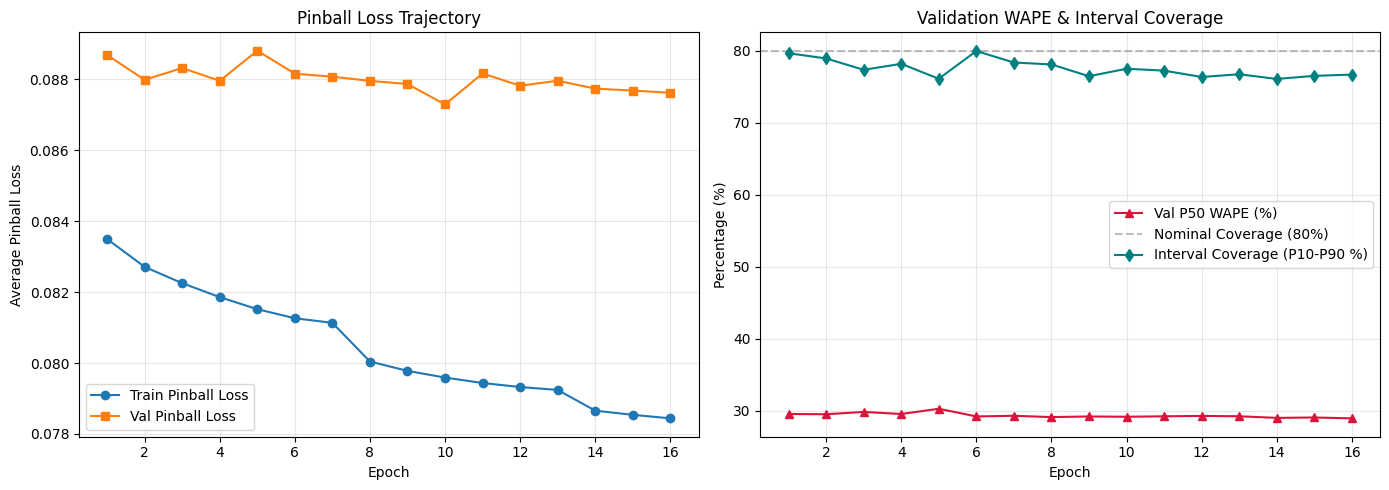

In [8]:
# =====================================================================
# CELL 4: Train Exact Champion Quantile TFT
# =====================================================================
import time
import torch
import numpy as np
import matplotlib.pyplot as plt

# Exact Optuna champion hyperparameters
LEARNING_RATE = 0.002595942550311264
WEIGHT_DECAY  = 2.6587543983272695e-05
MAX_EPOCHS    = 35
PATIENCE      = 6
CHECKPOINT    = "tft_quantile_champion.pth"

optimizer = torch.optim.AdamW(
    champion_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    total_samples = 0

    for batch in loader:
        past_x   = batch["past_x"].to(device)
        future_x = batch["future_x"].to(device)
        static_x = batch["static_x"].to(device)
        y        = batch["y"].to(device)

        optimizer.zero_grad()
        preds = model(past_x, future_x, static_x)
        loss  = criterion(preds, y)
        loss.backward()

        # Gradient clipping to ensure stable training
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        batch_sz = len(y)
        running_loss += loss.item() * batch_sz
        total_samples += batch_sz

    return running_loss / total_samples

print("=" * 70)
print("STARTING EXACT OPTUNA CHAMPION QUANTILE TFT TRAINING")
print("  - Target Quantiles:      P10, P50, P90")
print("  - Hidden Size:           32")
print("  - Attention Heads:       2")
print("  - Dropout:               0.25")
print(f"  - Learning Rate:         {LEARNING_RATE:.6f}")
print(f"  - Weight Decay:          {WEIGHT_DECAY:.6e}")
print(f"  - Max Epochs:            {MAX_EPOCHS}")
print(f"  - Early Stopping:        Patience = {PATIENCE}")
print("=" * 70)

history = {
    "train_loss": [], "val_loss": [], "val_wape": [],
    "val_coverage": [], "val_q10": [], "val_q50": [], "val_q90": []
}

best_val_loss = float("inf")
epochs_without_improvement = 0
start_time = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    ep_start = time.time()

    train_loss = train_one_epoch(champion_model, train_loader, optimizer, criterion, DEVICE)
    val_m = evaluate_quantiles(champion_model, val_loader, criterion, DEVICE, target_scaler)
    val_loss = val_m["loss"]
    val_wape = val_m["wape"]
    val_cov  = val_m["coverage"]

    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_wape"].append(val_wape)
    history["val_coverage"].append(val_cov)
    history["val_q10"].append(val_m["q10_risk"])
    history["val_q50"].append(val_m["q50_risk"])
    history["val_q90"].append(val_m["q90_risk"])

    # Check for improvement on Validation Pinball Loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save({
            "epoch": epoch,
            "model_state_dict": champion_model.state_dict(),
            "best_val_loss": best_val_loss,
            "val_wape": val_wape,
            "val_coverage": val_cov,
            "cat_cardinalities": cat_cardinalities,
            "cat_categories": cat_categories
        }, CHECKPOINT)
        save_tag = f" ⭐ [BEST MODEL SAVED - Loss: {best_val_loss:.4f}]"
    else:
        epochs_without_improvement += 1
        save_tag = f"   [No improvement: {epochs_without_improvement}/{PATIENCE}]"

    ep_duration = time.time() - ep_start
    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS:02d} ({ep_duration:.1f}s, lr={current_lr:.1e}) | "
        f"Train: {train_loss:.4f} | Val: {val_loss:.4f} | P50 WAPE: {val_wape:.2f}% | "
        f"Coverage (P10-P90): {val_cov:.1f}%{save_tag}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\n⏹ Early stopping triggered after {epoch} epochs (no improvement for {PATIENCE} consecutive epochs).")
        break

total_duration = time.time() - start_time
print("=" * 70)
print(f"✅ Training completed in {total_duration / 60:.2f} minutes!")
print(f"   Best Validation Loss: {best_val_loss:.4f}")
print("=" * 70)

# Plot Training & Validation Curves
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], label="Train Pinball Loss", marker='o')
plt.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], label="Val Pinball Loss", marker='s')
plt.title("Pinball Loss Trajectory")
plt.xlabel("Epoch")
plt.ylabel("Average Pinball Loss")
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, len(history["val_wape"]) + 1), history["val_wape"], label="Val P50 WAPE (%)", color="crimson", marker='^')
plt.axhline(y=80.0, color='gray', linestyle='--', label='Nominal Coverage (80%)', alpha=0.5)
plt.plot(range(1, len(history["val_coverage"]) + 1), history["val_coverage"], label="Interval Coverage (P10-P90 %)", color="teal", marker='d')
plt.title("Validation WAPE & Interval Coverage")
plt.xlabel("Epoch")
plt.ylabel("Percentage (%)")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("tft_quantile_training_curves.png", dpi=150)
plt.show()

1. LOADING BEST CHAMPION CHECKPOINT...
✅ Loaded weights from Epoch 10 (Best Val Loss: 0.0873)

2. Running inference on Test Set (3,237 sequences)...


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.7.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(



📊 FINAL TEST SET EVALUATION REPORT (QUANTILE TFT)
  - Average Pinball Loss:         0.0873
  - Empirical Coverage (P10-P90): 78.79%  (Nominal Target: 80.00%)
  - Median (P50) WAPE:            28.09%
  - Median (P50) MAE:             12.43 units
  - Median (P50) RMSE:            35.23 units
  - q10-Risk (Under-prediction):  0.1097
  - q50-Risk (Median Risk):       0.2809
  - q90-Risk (Over-prediction):   0.1606


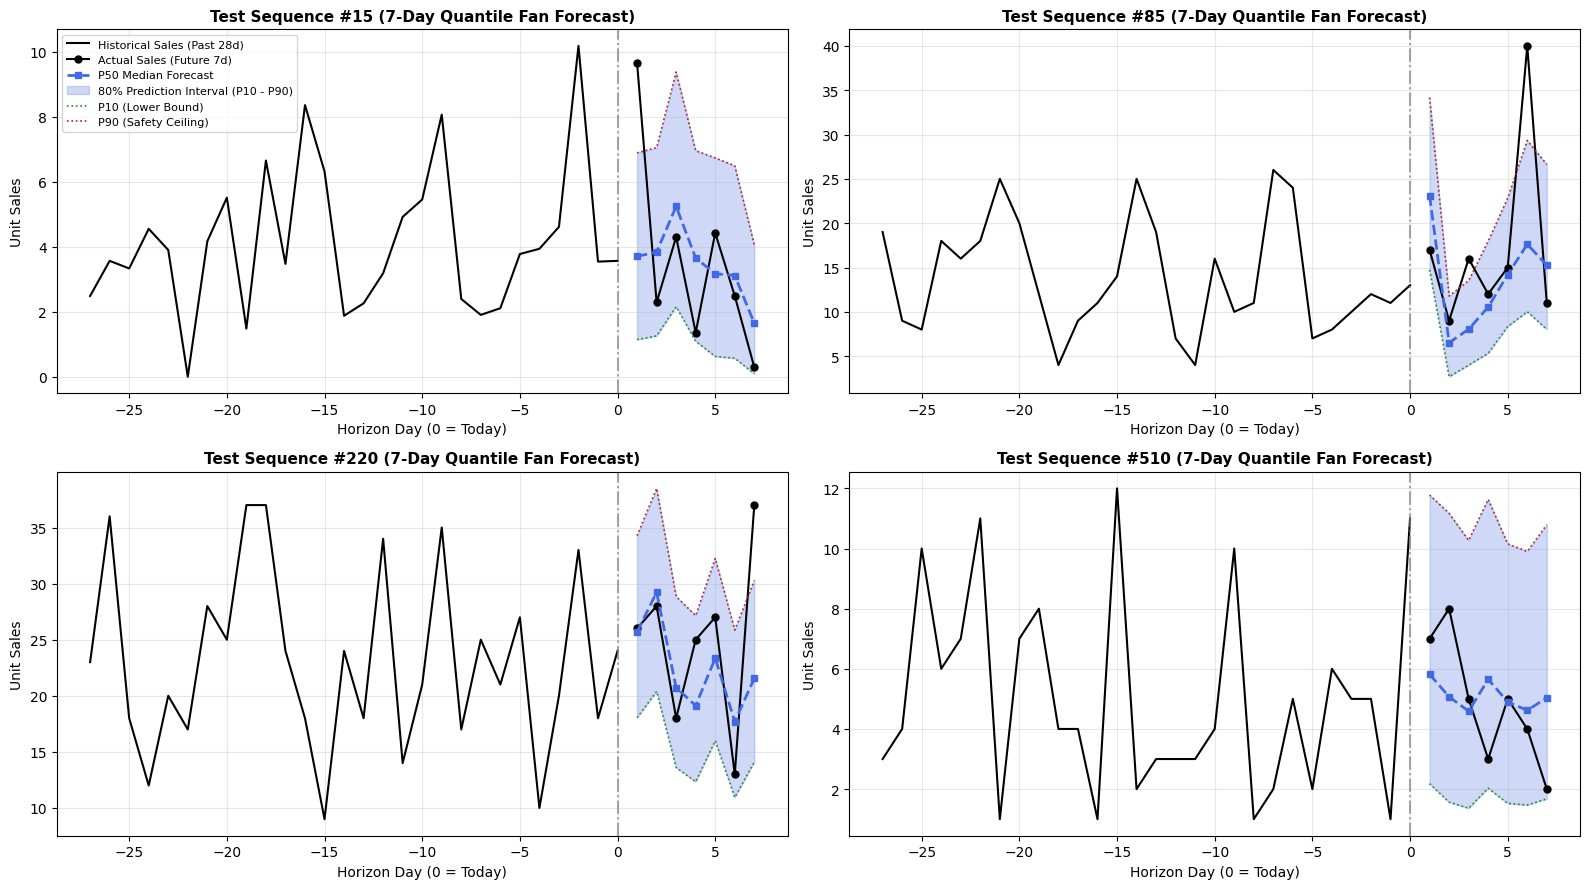

✅ Saved publication fan charts to 'tft_quantile_fan_forecasts.png'!

5. Exporting forecasts to 'tft_quantile_forecasts.csv'...
✅ Exported 22,659 forecast rows to 'tft_quantile_forecasts.csv'!


In [13]:
# =====================================================================
# CELL 5: Test Set Evaluation, Fan Charts & Forecast Export
# =====================================================================
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

print("=" * 70)
print("1. LOADING BEST CHAMPION CHECKPOINT...")
# Added weights_only=False for PyTorch 2.6 compatibility
checkpoint = torch.load("tft_quantile_champion.pth", map_location=DEVICE, weights_only=False)
champion_model.load_state_dict(checkpoint["model_state_dict"])
champion_model.eval()
print(f"✅ Loaded weights from Epoch {checkpoint['epoch']} (Best Val Loss: {checkpoint['best_val_loss']:.4f})")
print("=" * 70)

# 2. Run Comprehensive Inference on the Test Set
print("\n2. Running inference on Test Set (3,237 sequences)...")
test_loss = 0.0
all_p10, all_p50, all_p90, all_y_raw = [], [], [], []
all_past_raw, all_seq_idx = [], []

scaler_dict = joblib.load("target_sales_scaler.joblib")
target_scaler = scaler_dict["target_scaler"]

with torch.no_grad():
    for batch in test_loader:
        past_x   = batch["past_x"].to(DEVICE)
        future_x = batch["future_x"].to(DEVICE)
        static_x = batch["static_x"].to(DEVICE)
        y        = batch["y"].to(DEVICE)
        y_raw    = batch["y_raw"].cpu().numpy()

        preds = champion_model(past_x, future_x, static_x)
        loss  = criterion(preds, y)
        test_loss += loss.item() * len(y)

        # Invert from scaled space back to raw unit sales
        p10_scaled = preds[:, :, 0].cpu().numpy()
        p50_scaled = preds[:, :, 1].cpu().numpy()
        p90_scaled = preds[:, :, 2].cpu().numpy()

        p10_raw = np.expm1(target_scaler.inverse_transform(p10_scaled)).clip(min=0.0)
        p50_raw = np.expm1(target_scaler.inverse_transform(p50_scaled)).clip(min=0.0)
        p90_raw = np.expm1(target_scaler.inverse_transform(p90_scaled)).clip(min=0.0)

        # Invert past sales (first column of past_x) for fan plotting
        past_scaled = past_x[:, :, 0].cpu().numpy()
        past_raw = np.expm1(target_scaler.inverse_transform(past_scaled)).clip(min=0.0)

        all_p10.append(p10_raw)
        all_p50.append(p50_raw)
        all_p90.append(p90_raw)
        all_y_raw.append(y_raw)
        all_past_raw.append(past_raw)

p10_arr  = np.vstack(all_p10)       # [3237, 7]
p50_arr  = np.vstack(all_p50)       # [3237, 7]
p90_arr  = np.vstack(all_p90)       # [3237, 7]
y_arr    = np.vstack(all_y_raw)     # [3237, 7]
past_arr = np.vstack(all_past_raw)  # [3237, 28]

# 3. Calculate Research Metrics
avg_test_pinball = test_loss / len(test_loader.dataset)
total_actual = np.sum(y_arr)
abs_errors   = np.abs(y_arr - p50_arr)
sq_errors    = (y_arr - p50_arr) ** 2

test_wape = (np.sum(abs_errors) / total_actual) * 100.0
test_mae  = np.mean(abs_errors)
test_rmse = np.sqrt(np.mean(sq_errors))

# Coverage (% of actuals inside [P10, P90] interval)
inside = (y_arr >= p10_arr) & (y_arr <= p90_arr)
test_coverage = np.mean(inside) * 100.0

# Quantile Risks
q10_risk = (2.0 * np.sum(np.maximum(0.1 * (y_arr - p10_arr), -0.9 * (y_arr - p10_arr)))) / total_actual
q50_risk = (2.0 * np.sum(np.maximum(0.5 * (y_arr - p50_arr), -0.5 * (y_arr - p50_arr)))) / total_actual
q90_risk = (2.0 * np.sum(np.maximum(0.9 * (y_arr - p90_arr), -0.1 * (y_arr - p90_arr)))) / total_actual

print("\n" + "=" * 70)
print("📊 FINAL TEST SET EVALUATION REPORT (QUANTILE TFT)")
print("=" * 70)
print(f"  - Average Pinball Loss:         {avg_test_pinball:.4f}")
print(f"  - Empirical Coverage (P10-P90): {test_coverage:.2f}%  (Nominal Target: 80.00%)")
print(f"  - Median (P50) WAPE:            {test_wape:.2f}%")
print(f"  - Median (P50) MAE:             {test_mae:.2f} units")
print(f"  - Median (P50) RMSE:            {test_rmse:.2f} units")
print(f"  - q10-Risk (Under-prediction):  {q10_risk:.4f}")
print(f"  - q50-Risk (Median Risk):       {q50_risk:.4f}")
print(f"  - q90-Risk (Over-prediction):   {q90_risk:.4f}")
print("=" * 70)

# 4. Generate Quantile Fan Charts (4 Sample SKU Sequences)
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
axes = axes.flatten()

sample_indices = [15, 85, 220, 510]  # diverse sample sequences
past_days = np.arange(-27, 1)
fut_days  = np.arange(1, 8)

for ax_idx, seq_i in enumerate(sample_indices):
    ax = axes[ax_idx]

    # Historical context (Past 28 days)
    ax.plot(past_days, past_arr[seq_i], color="black", linewidth=1.5, label="Historical Sales (Past 28d)")

    # Ground Truth Future (Next 7 days)
    ax.plot(fut_days, y_arr[seq_i], color="black", marker="o", markersize=5, linestyle="-", label="Actual Sales (Future 7d)")

    # P50 Median Forecast
    ax.plot(fut_days, p50_arr[seq_i], color="royalblue", marker="s", markersize=5, linestyle="--", linewidth=2, label="P50 Median Forecast")

    # P10 - P90 Uncertainty Fan (Confidence Interval)
    ax.fill_between(fut_days, p10_arr[seq_i], p90_arr[seq_i], color="royalblue", alpha=0.25, label="80% Prediction Interval (P10 - P90)")
    ax.plot(fut_days, p10_arr[seq_i], color="forestgreen", linestyle=":", linewidth=1.2, label="P10 (Lower Bound)")
    ax.plot(fut_days, p90_arr[seq_i], color="firebrick", linestyle=":", linewidth=1.2, label="P90 (Safety Ceiling)")

    ax.axvline(x=0, color="gray", linestyle="-.", alpha=0.7)
    ax.set_title(f"Test Sequence #{seq_i} (7-Day Quantile Fan Forecast)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Horizon Day (0 = Today)")
    ax.set_ylabel("Unit Sales")
    ax.grid(True, alpha=0.3)
    if ax_idx == 0:
        ax.legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.savefig("tft_quantile_fan_forecasts.png", dpi=180)
plt.show()
print("✅ Saved publication fan charts to 'tft_quantile_fan_forecasts.png'!")

# 5. Export Flattened Forecasts to CSV for Inventory Optimization
print("\n5. Exporting forecasts to 'tft_quantile_forecasts.csv'...")
rows = []
for seq_i in range(len(y_arr)):
    for day_h in range(7):
        rows.append({
            "sequence_idx": seq_i,
            "forecast_day": day_h + 1,
            "p10_forecast": round(float(p10_arr[seq_i, day_h]), 2),
            "p50_forecast": round(float(p50_arr[seq_i, day_h]), 2),
            "p90_forecast": round(float(p90_arr[seq_i, day_h]), 2),
            "actual_sales": round(float(y_arr[seq_i, day_h]), 2)
        })

df_out = pd.DataFrame(rows)
df_out.to_csv("tft_quantile_forecasts.csv", index=False)
print(f"✅ Exported {len(df_out):,} forecast rows to 'tft_quantile_forecasts.csv'!")

📊 COMPREHENSIVE TEST SET EVALUATION BENCHMARK
  [POINT ACCURACY - P50 MEDIAN]
  • MAE:                    12.433 units
  • RMSE:                   35.227 units
  • RMSE / MAE Ratio:       2.833
  • R² Score:               0.7425  (74.25% variance explained)
  • WAPE:                   28.09%
  • SMAPE:                  37.15%
---------------------------------------------------------------------------
  [UNCERTAINTY & QUANTILE CALIBRATION - P10, P50, P90]
  • 80% Interval Coverage:  78.87%  (Nominal Goal: 80.00%)
  • Avg Interval Width:     35.72 units (PINAW: 2.16%)
  • q10-Risk (Under-pred):  0.1097
  • q50-Risk (Median Risk): 0.2809
  • q90-Risk (Over-pred):   0.1606

📅 HORIZON-BY-HORIZON PERFORMANCE BREAKDOWN (DAY 1 TO 7):


,Day,MAE,RMSE,RMSE/MAE,R² Score,WAPE (%),Coverage (%),Avg Width
0,Day +1,12.68,36.77,2.90,0.7490,27.30,79.21,35.95
1,Day +2,12.31,35.66,2.90,0.7496,27.39,79.67,34.99
2,Day +3,12.37,34.91,2.82,0.7533,27.58,79.30,35.86
3,Day +4,12.30,32.97,2.68,0.7698,27.31,78.65,36.23
4,Day +5,12.39,33.38,2.69,0.7480,27.88,78.99,36.21
5,Day +6,12.58,36.22,2.88,0.7239,29.20,78.10,35.91
6,Day +7,12.39,36.49,2.95,0.6988,30.21,78.19,34.90


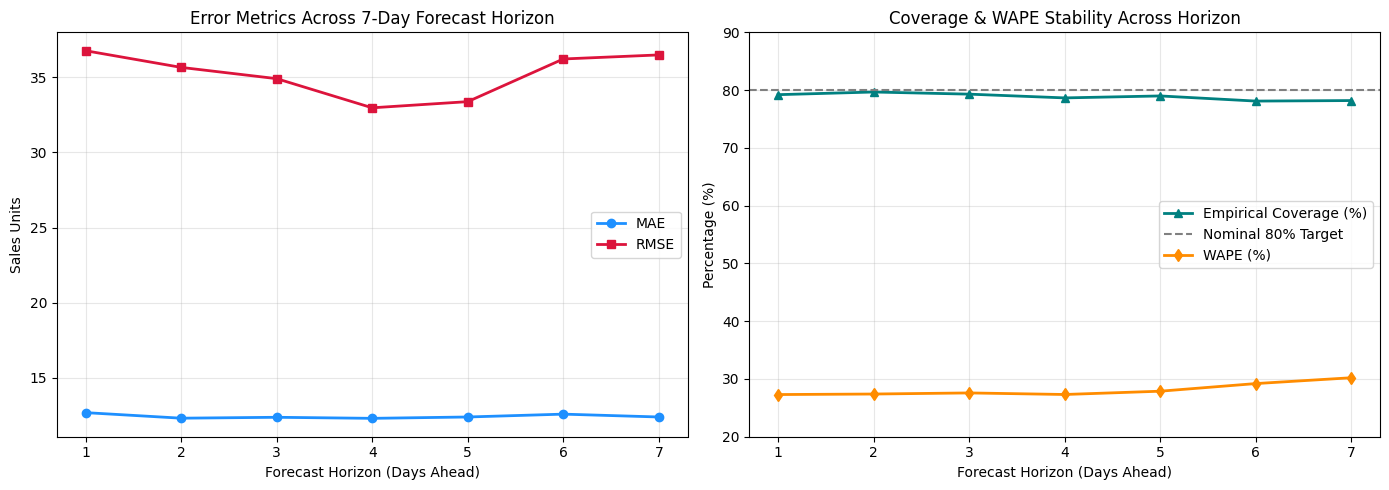

✅ Saved horizon analysis plot to 'tft_horizon_breakdown.png'!


In [14]:
# =====================================================================
# CELL 6: Comprehensive Statistical & Diagnostic Testing Battery
# =====================================================================
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# 1. Load exported forecasts
df_q = pd.read_csv("tft_quantile_forecasts.csv")

y_true = df_q["actual_sales"].values
p10    = df_q["p10_forecast"].values
p50    = df_q["p50_forecast"].values
p90    = df_q["p90_forecast"].values

# 2. Overall Point-Accuracy Metrics (P50 Median Forecast)
mae   = mean_absolute_error(y_true, p50)
mse   = mean_squared_error(y_true, p50)
rmse  = np.sqrt(mse)
ratio = rmse / mae if mae > 0 else 0
r2    = r2_score(y_true, p50)

total_actual = np.sum(y_true)
wape  = (np.sum(np.abs(y_true - p50)) / total_actual) * 100.0
smape = np.mean(2.0 * np.abs(y_true - p50) / (np.abs(y_true) + np.abs(p50) + 1e-5)) * 100.0

# 3. Overall Uncertainty & Quantile Calibration Metrics
inside_interval = (y_true >= p10) & (y_true <= p90)
coverage_80     = np.mean(inside_interval) * 100.0

# Sharpness / Average Prediction Interval Width
avg_interval_width = np.mean(p90 - p10)
pinaw = (avg_interval_width / (np.max(y_true) - np.min(y_true))) * 100.0  # Normalized width %

# Quantile Pinball Risks
q10_risk = (2.0 * np.sum(np.maximum(0.1 * (y_true - p10), -0.9 * (y_true - p10)))) / total_actual
q50_risk = (2.0 * np.sum(np.maximum(0.5 * (y_true - p50), -0.5 * (y_true - p50)))) / total_actual
q90_risk = (2.0 * np.sum(np.maximum(0.9 * (y_true - p90), -0.1 * (y_true - p90)))) / total_actual
avg_pinball_loss = (q10_risk + q50_risk + q90_risk) / 6.0  # normalized pinball

print("=" * 75)
print("📊 COMPREHENSIVE TEST SET EVALUATION BENCHMARK")
print("=" * 75)
print(f"  [POINT ACCURACY - P50 MEDIAN]")
print(f"  • MAE:                    {mae:.3f} units")
print(f"  • RMSE:                   {rmse:.3f} units")
print(f"  • RMSE / MAE Ratio:       {ratio:.3f}")
print(f"  • R² Score:               {r2:.4f}  ({r2*100:.2f}% variance explained)")
print(f"  • WAPE:                   {wape:.2f}%")
print(f"  • SMAPE:                  {smape:.2f}%")
print("-" * 75)
print(f"  [UNCERTAINTY & QUANTILE CALIBRATION - P10, P50, P90]")
print(f"  • 80% Interval Coverage:  {coverage_80:.2f}%  (Nominal Goal: 80.00%)")
print(f"  • Avg Interval Width:     {avg_interval_width:.2f} units (PINAW: {pinaw:.2f}%)")
print(f"  • q10-Risk (Under-pred):  {q10_risk:.4f}")
print(f"  • q50-Risk (Median Risk): {q50_risk:.4f}")
print(f"  • q90-Risk (Over-pred):   {q90_risk:.4f}")
print("=" * 75)

# 4. Multi-Horizon Breakdown: Day 1 through Day 7
day_stats = []
for day in range(1, 8):
    sub = df_q[df_q["forecast_day"] == day]
    y_d = sub["actual_sales"].values
    p10_d = sub["p10_forecast"].values
    p50_d = sub["p50_forecast"].values
    p90_d = sub["p90_forecast"].values

    d_mae   = mean_absolute_error(y_d, p50_d)
    d_rmse  = np.sqrt(mean_squared_error(y_d, p50_d))
    d_r2    = r2_score(y_d, p50_d)
    d_wape  = (np.sum(np.abs(y_d - p50_d)) / np.sum(y_d)) * 100.0
    d_cov   = np.mean((y_d >= p10_d) & (y_d <= p90_d)) * 100.0
    d_width = np.mean(p90_d - p10_d)

    day_stats.append({
        "Day": f"Day +{day}",
        "MAE": round(d_mae, 2),
        "RMSE": round(d_rmse, 2),
        "RMSE/MAE": round(d_rmse / d_mae, 2),
        "R² Score": round(d_r2, 4),
        "WAPE (%)": round(d_wape, 2),
        "Coverage (%)": round(d_cov, 2),
        "Avg Width": round(d_width, 2)
    })

df_days = pd.DataFrame(day_stats)
print("\n📅 HORIZON-BY-HORIZON PERFORMANCE BREAKDOWN (DAY 1 TO 7):")
display(df_days)

# 5. Horizon Degradation Plot
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, 8), df_days["MAE"], marker='o', label="MAE", color="dodgerblue", linewidth=2)
plt.plot(range(1, 8), df_days["RMSE"], marker='s', label="RMSE", color="crimson", linewidth=2)
plt.title("Error Metrics Across 7-Day Forecast Horizon")
plt.xlabel("Forecast Horizon (Days Ahead)")
plt.ylabel("Sales Units")
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, 8), df_days["Coverage (%)"], marker='^', label="Empirical Coverage (%)", color="teal", linewidth=2)
plt.axhline(80.0, color='gray', linestyle='--', label="Nominal 80% Target")
plt.plot(range(1, 8), df_days["WAPE (%)"], marker='d', label="WAPE (%)", color="darkorange", linewidth=2)
plt.title("Coverage & WAPE Stability Across Horizon")
plt.xlabel("Forecast Horizon (Days Ahead)")
plt.ylabel("Percentage (%)")
plt.ylim(20, 90)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("tft_horizon_breakdown.png", dpi=150)
plt.show()
print("✅ Saved horizon analysis plot to 'tft_horizon_breakdown.png'!")

In [12]:
from google.colab import files

print("📥 Downloading best champion model checkpoint...")
files.download("tft_quantile_champion.pth")

📥 Downloading best champion model checkpoint...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>